# Understanding Adam - Adaptive Moment Estimation
**ICOM6015 - Exercises from D2L Section 12.10.5**

Reference: A. Zhang, Z. C. Lipton, M. Li, and A. J. Smola, *Dive into Deep Learning*, Sec. 12.10 "Adam."

## Part 0 — Setup: data, model, and optimizers (Adam, Yogi) from scratch
We reproduce the setup used in D2L (`train_ch11`): linear regression on the NASA airfoil self-noise dataset
(1500 samples, standardized features), minibatch size 10, 2 epochs, squared loss.
All experiments in later sections reuse these functions.

In [3]:
# --- Python standard library (built in, nothing to install) ---
import sys                  # info about the running Python; used to confirm we are in the .venv
import hashlib              # computes file hashes (SHA-1) to verify the dataset downloaded intact
import urllib.request       # downloads files from a URL (the airfoil dataset)
from pathlib import Path    # handles file/folder paths in an OS-independent way

# --- Third-party libraries (installed in the .venv with pip) ---
import numpy as np                  # numerical arrays and linear algebra: data, gradients, Adam/Yogi math
import matplotlib                   # plotting library (imported only to print its version)
import matplotlib.pyplot as plt     # matplotlib's plotting interface: loss curves and figures

In [4]:
# random seed
SEED = 0 
# point to the folder paths to save the data/figures
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
# create the folders if they don't exist; no error if they already do
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

### 0.1 Data
Airfoil self-noise dataset (downloaded from D2L's data server, integrity verified with SHA-1).
Each column is standardized to zero mean and unit variance; the last column is the target.

In [5]:
# dataset URL and expected hash (same as D2L)
URL = "http://d2l-data.s3-accelerate.amazonaws.com/airfoil_self_noise.dat"
SHA1 = "76e5be1548fd8222e5074cf0faae75edff8cf93f"
path = DATA_DIR / "airfoil_self_noise.dat"

# download once and verify the file is intact
if not path.exists():
    urllib.request.urlretrieve(URL, path)
assert hashlib.sha1(path.read_bytes()).hexdigest() == SHA1, "corrupted file"

# load and standardize each column (mean 0, std 1)
data = np.genfromtxt(path, delimiter="\t")
data = (data - data.mean(axis=0)) / data.std(axis=0)

# first 1500 rows: 5 input features (X) and the target noise level (y)
X, y = data[:1500, :-1], data[:1500, -1:]
print(X.shape, y.shape)

(1500, 5) (1500, 1)


### 0.2 Model, loss, and gradient
Linear model $\hat{y} = Xw + b$ with squared loss. The analytic gradient is checked against finite differences.

In [9]:
def predict(X, w, b):
    """Linear model prediction.
    Args:
        X: inputs, shape (B, d).
        w: weights, shape (d, 1).
        b: bias, shape (1, 1).
    Returns:
        Predictions y_hat = Xw + b, shape (B, 1).
    """
    return X @ w + b

def loss(X, y, w, b):
    """Squared loss averaged over samples: mean((y_hat - y)^2 / 2).
    Args:
        X: inputs, shape (B, d).
        y: targets, shape (B, 1).
        w, b: model parameters.
    Returns:
        Scalar loss.
    """
    return float(np.mean((predict(X, w, b) - y) ** 2) / 2)

def gradients(X, y, w, b):
    """Analytic gradient of the loss with respect to w and b.
    Args:
        X: inputs, shape (B, d).
        y: targets, shape (B, 1).
        w, b: model parameters.
    Returns:
        Dict {"w": dL/dw, "b": dL/db} with the same shapes as w and b.
    """
    r = predict(X, w, b) - y
    return {"w": X.T @ r / len(X), "b": r.mean(axis=0, keepdims=True)}

In [10]:
# random test point
rng = np.random.default_rng(SEED)
w, b = rng.normal(0, 1, (5, 1)), rng.normal(0, 1, (1, 1))
g = gradients(X, y, w, b)

# numerical gradient with central differences
h = 1e-6
num_w = np.zeros_like(w)
for i in range(len(w)):
    e = np.zeros_like(w); e[i] = h
    num_w[i] = (loss(X, y, w + e, b) - loss(X, y, w - e, b)) / (2 * h)
num_b = (loss(X, y, w, b + h) - loss(X, y, w, b - h)) / (2 * h)

# errors should be ~1e-10
print("max error w:", np.abs(num_w - g["w"]).max())
print("max error b:", abs(num_b - g["b"].item()))

max error w: 7.710050566739346e-11
max error b: 1.6279344539071872e-10


### 0.3 Optimizers
**Adam:**
$$v_t = \beta_1 v_{t-1} + (1-\beta_1) g_t, \qquad s_t = \beta_2 s_{t-1} + (1-\beta_2) g_t^2$$
$$\hat{v}_t = \frac{v_t}{1-\beta_1^t}, \qquad \hat{s}_t = \frac{s_t}{1-\beta_2^t}, \qquad x_t = x_{t-1} - \frac{\eta\, \hat{v}_t}{\sqrt{\hat{s}_t} + \epsilon}$$

**Yogi** only changes the second moment:
$$s_t = s_{t-1} + (1-\beta_2)\, g_t^2 \odot \operatorname{sgn}(g_t^2 - s_{t-1})$$

In [11]:
def init_states(params):
    """Create the optimizer state: first moment v and second moment s, both at 0.
    Args:
        params: dict of parameter arrays, e.g. {"w": ..., "b": ...}.
    Returns:
        Dict {name: {"v": zeros, "s": zeros}} with one entry per parameter.
    """
    return {k: {"v": np.zeros_like(p), "s": np.zeros_like(p)} for k, p in params.items()}

def adam(params, grads, states, t, lr, beta1=0.9, beta2=0.999, eps=1e-6):
    """One Adam step. Updates params and states in place.
    Args:
        params: dict of parameter arrays.
        grads: dict of gradients, same keys as params.
        states: optimizer state from init_states.
        t: step number, starting at 1 (used for bias correction).
        lr: learning rate eta.
        beta1: decay rate of the first moment.
        beta2: decay rate of the second moment.
        eps: small constant to avoid division by zero.
    """
    for k in params:
        v, s, g = states[k]["v"], states[k]["s"], grads[k]
        # moving averages of the gradient and the squared gradient
        v[:] = beta1 * v + (1 - beta1) * g
        s[:] = beta2 * s + (1 - beta2) * g**2
        # bias correction
        v_hat = v / (1 - beta1**t)
        s_hat = s / (1 - beta2**t)
        # parameter update
        params[k] -= lr * v_hat / (np.sqrt(s_hat) + eps)

def yogi(params, grads, states, t, lr, beta1=0.9, beta2=0.999, eps=1e-3):
    """One Yogi step. Same as adam() except for the second-moment update.
    Args:
        Same as adam(). D2L uses eps=1e-3 for Yogi.
    """
    for k in params:
        v, s, g = states[k]["v"], states[k]["s"], grads[k]
        v[:] = beta1 * v + (1 - beta1) * g
        # only difference from Adam: additive second-moment update
        s[:] = s + (1 - beta2) * g**2 * np.sign(g**2 - s)
        v_hat = v / (1 - beta1**t)
        s_hat = s / (1 - beta2**t)
        params[k] -= lr * v_hat / (np.sqrt(s_hat) + eps)

### 0.4 Training loop
Fixed seed: same initialization and minibatch order in every run, so only the optimizer settings change.

In [12]:
def train(optimizer, hp, num_epochs=2, batch_size=10, seed=SEED):
    """Train linear regression with minibatches (equivalent to d2l.train_ch11).
    The same seed gives the same initialization and minibatch order,
    so runs differ only in the optimizer and its hyperparameters.
    Args:
        optimizer: update function, adam or yogi.
        hp: optimizer hyperparameters, e.g. {"lr": 0.01}.
        num_epochs: passes over the dataset.
        batch_size: samples per minibatch.
        seed: random seed.
    Returns:
        history: array of [epoch, full-dataset loss], recorded every 200 samples.
        params: final parameters {"w", "b"}.
    """
    rng = np.random.default_rng(seed)
    params = {"w": rng.normal(0, 0.01, (X.shape[1], 1)), "b": np.zeros((1, 1))}
    states = init_states(params)
    t, seen = 0, 0
    history = [(0.0, loss(X, y, params["w"], params["b"]))]

    for epoch in range(num_epochs):
        # shuffle the data every epoch
        idx = rng.permutation(len(X))
        for start in range(0, len(X), batch_size):
            # one optimizer step on a minibatch
            batch = idx[start:start + batch_size]
            grads = gradients(X[batch], y[batch], params["w"], params["b"])
            t += 1
            optimizer(params, grads, states, t, **hp)
            # record the full-dataset loss every 200 samples
            seen += len(batch)
            if seen % 200 == 0:
                history.append((seen / len(X), loss(X, y, params["w"], params["b"])))
    return np.array(history), params

### 0.5 Sanity check
D2L reports a final loss of about 0.24 for both optimizers with $\eta = 0.01$.

Adam final loss: 0.2436
Yogi final loss: 0.2433


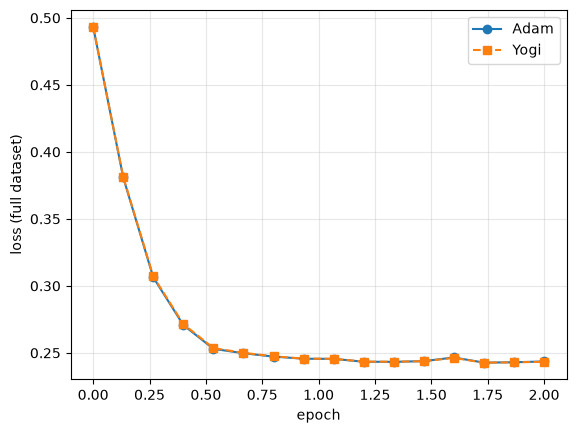

In [13]:
# same conditions for both optimizers (D2L reports ~0.24)
hist_adam, _ = train(adam, {"lr": 0.01})
hist_yogi, _ = train(yogi, {"lr": 0.01})
print(f"Adam final loss: {hist_adam[-1, 1]:.4f}")
print(f"Yogi final loss: {hist_yogi[-1, 1]:.4f}")

# loss curves
plt.plot(*hist_adam.T, "o-", label="Adam")
plt.plot(*hist_yogi.T, "s--", label="Yogi")
plt.xlabel("epoch"); plt.ylabel("loss (full dataset)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Exercise 1 - Learning rate
*Adjust the learning rate and observe and analyze the experimental results.*

**Setup:** Adam on the Part 0 problem. Only the learning rate changes: $\eta \in \{10^{-4}, 10^{-3}, 10^{-2}, 10^{-1}, 1\}$.
Everything else is fixed ($\beta_1=0.9$, $\beta_2=0.999$, $\epsilon=10^{-6}$, batch size 10, 2 epochs = 300 steps).
Each learning rate is run with 5 seeds (different initialization and minibatch order).
The optimal loss, computed exactly with least squares, is used as a reference.

**Expectation (before running):** Since Adam moves each parameter by roughly $\eta$ per step,
the smallest learning rate should change the weights the least and take the longest to approach
the minimum loss: with $\eta = 10^{-4}$, each weight can move at most $300 \times 10^{-4} = 0.03$ in total.
A large learning rate ($\eta = 1$) should make steps big enough to overshoot the minimum,
so the loss may jump around instead of settling.

In [14]:
# optimal loss: exact least-squares solution (the best any optimizer can reach)
A = np.hstack([X, np.ones((len(X), 1))])
sol = np.linalg.lstsq(A, y, rcond=None)[0]
OPT_LOSS = loss(X, y, sol[:-1], sol[-1:])
print(f"Optimal loss: {OPT_LOSS:.4f}")

Optimal loss: 0.2417


In [15]:
# learning rates to compare and seeds for repetition
LRS = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
SEEDS = range(5)

In [16]:
# learning rates to compare and seeds for repetition
LRS = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
SEEDS = range(5)

# run every (learning rate, seed) pair
results = {lr: [train(adam, {"lr": lr}, seed=s)[0] for s in SEEDS] for lr in LRS}

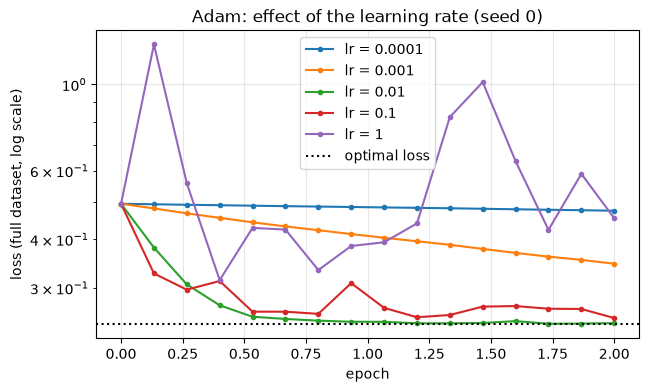

In [17]:
# loss curves for seed 0, with the optimal loss as reference
fig, ax = plt.subplots(figsize=(7, 4))
for lr in LRS:
    ax.plot(*results[lr][0].T, "o-", ms=3, label=f"lr = {lr:g}")
ax.axhline(OPT_LOSS, color="k", ls=":", label="optimal loss")
ax.set_yscale("log")
ax.set_xlabel("epoch"); ax.set_ylabel("loss (full dataset, log scale)")
ax.set_title("Adam: effect of the learning rate (seed 0)")
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "ex1_learning_rates.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
# summary over seeds: final loss (mean ± std), best loss reached, and gap to the optimum
print(f"{'lr':>8} | {'final loss':>16} | {'best loss':>9} | {'final - optimal':>15}")
for lr in LRS:
    final = np.array([h[-1, 1] for h in results[lr]])
    best = np.array([h[:, 1].min() for h in results[lr]])
    print(f"{lr:>8g} | {final.mean():.4f} ± {final.std():.4f} | {best.mean():>9.4f} | {final.mean() - OPT_LOSS:>15.4f}")

      lr |       final loss | best loss | final - optimal
  0.0001 | 0.4753 ± 0.0036 |    0.4753 |          0.2336
   0.001 | 0.3415 ± 0.0024 |    0.3415 |          0.0998
    0.01 | 0.2436 ± 0.0010 |    0.2427 |          0.0019
     0.1 | 0.2707 ± 0.0171 |    0.2501 |          0.0290
       1 | 0.8903 ± 0.6456 |    0.3112 |          0.6486


### Results
| $\eta$ | Final loss (mean ± std, 5 seeds) | Best loss | Final − optimal |
|---|---|---|---|
| $10^{-4}$ | 0.4753 ± 0.0036 | 0.4753 | 0.2336 |
| $10^{-3}$ | 0.3415 ± 0.0024 | 0.3415 | 0.0998 |
| $10^{-2}$ | 0.2436 ± 0.0010 | 0.2427 | 0.0019 |
| $10^{-1}$ | 0.2707 ± 0.0171 | 0.2501 | 0.0290 |
| $1$ | 0.8903 ± 0.6456 | 0.3112 | 0.6486 |

Optimal loss (least squares): 0.2417.

### Observations
- $\eta = 10^{-4}$ and $10^{-3}$: the loss decreases monotonically (best = final) but stays far from the optimum after 2 epochs.
- $\eta = 10^{-2}$: fastest stable decrease; the final loss is within 0.002 of the optimum, with very low variance across seeds.
- $\eta = 10^{-1}$: the loss drops quickly at first but then fluctuates; the final loss is worse than the best loss reached.
- $\eta = 1$: the loss oscillates strongly, the final value is far above the best one, and the result varies widely between seeds. It does not diverge to infinity.

### Interpretation
- Adam's update is approximately $\eta \cdot \hat{v}_t / \sqrt{\hat{s}_t}$, where $\hat{v}_t / \sqrt{\hat{s}_t}$ has magnitude of order 1, so each parameter moves by roughly $\eta$ per step regardless of the gradient scale.
- Small $\eta$: in 300 steps a weight can move at most about $300\eta$ (0.03 for $\eta = 10^{-4}$), which is not enough to reach the minimum. These runs have not converged yet; they are slow, not unstable.
- Large $\eta$: steps are larger than the distance to the minimum, so the optimizer overshoots and keeps jumping around it. The best loss is reached and then lost. Because each step is bounded by about $\eta$, the loss stays bounded instead of diverging.
- Even the best $\eta$ does not reach the exact optimum: with noisy minibatch gradients and a constant $\eta$, Adam keeps taking steps of size about $\eta$ near the minimum and fluctuates around it (see Exercise 3).

### Conclusion
The expectation was confirmed: the learning rate sets the step size, creating a trade-off between speed (too small is slow) and stability (too large overshoots and oscillates). For this problem, $\eta = 10^{-2}$ gives the best balance. In neural network training the best $\eta$ depends on the problem, so it must be tuned, typically by trying values on a logarithmic scale as done here.

## Exercise 2 — Removing the bias correction
*Can you rewrite the momentum and second-moment updates such that they do not require a bias correction?*

### Why the bias appears
The memory starts at $v_0 = 0$. Unrolling the recursion $v_t = \beta v_{t-1} + (1-\beta) g_t$ shows that $v_t$ is a weighted sum of the gradients:
$$v_t = (1-\beta)\left(\beta^{t-1} g_1 + \beta^{t-2} g_2 + \cdots + g_t\right).$$
The weights add up to (geometric series)
$$(1-\beta)\left(1 + \beta + \cdots + \beta^{t-1}\right) = (1-\beta)\,\frac{1-\beta^t}{1-\beta} = 1-\beta^t$$
instead of 1: the missing weight $\beta^t$ belongs to the zero initial value. Therefore $v_t$ is smaller than it should be, especially in early steps
(e.g. with $\beta = 0.9$ and $g_1 = 5$: $v_1 = 0.5$, ten times too small). This error is the **bias**, and Adam removes it by dividing by $1-\beta^t$:
$\hat v_t = v_t / (1-\beta^t)$.

### Derivation
Starting point (D2L): **(A)** $v_t = \beta v_{t-1} + (1-\beta) g_t$ and **(B)** $\hat v_t = v_t/(1-\beta^t)$.
Goal: a recursion that gives $\hat v_t$ directly from $\hat v_{t-1}$ and $g_t$, without computing $v_t$ or correcting afterwards.

1. **Solve (B) for $v_t$** by multiplying both sides by $1-\beta^t$, which undoes the division:
$$v_t = (1-\beta^t)\,\hat v_t$$
2. **The same relation holds at every step**, so replacing $t$ by $t-1$:
$$v_{t-1} = (1-\beta^{t-1})\,\hat v_{t-1}$$
3. **Substitute** both expressions into (A). Each $v$ is replaced by an equal quantity, so the equality still holds, and only corrected values remain:
$$(1-\beta^t)\,\hat v_t = \beta\,(1-\beta^{t-1})\,\hat v_{t-1} + (1-\beta)\,g_t$$
4. **Simplify** with the distributive property and the product of powers ($\beta \cdot \beta^{t-1} = \beta^{t}$):
$$\beta\,(1-\beta^{t-1}) = \beta - \beta^t \quad\Rightarrow\quad (1-\beta^t)\,\hat v_t = (\beta-\beta^t)\,\hat v_{t-1} + (1-\beta)\,g_t$$
5. **Divide both sides by $1-\beta^t$** (each term separately). This is allowed because $0 \le \beta < 1$ implies $\beta^t < 1$, so $1-\beta^t \neq 0$:
$$\hat v_t = \frac{\beta-\beta^t}{1-\beta^t}\,\hat v_{t-1} + \frac{1-\beta}{1-\beta^t}\,g_t$$
6. **The two coefficients add up to 1.** They share the denominator, so the numerators are added; $+\beta$ and $-\beta$ cancel:
$$\frac{\beta-\beta^t}{1-\beta^t} + \frac{1-\beta}{1-\beta^t} = \frac{1-\beta^t}{1-\beta^t} = 1$$
This means $\hat v_t$ is a proper weighted average of the previous memory and the new gradient, which the uncorrected $v_t$ is not.
7. **Name the coefficient of $g_t$** as $\alpha_t$. Since both coefficients add up to 1, the other one is $1-\alpha_t$. The same steps applied to $s_t$ (with $\beta_2$ and $g_t^2$) give the second result:
$$\boxed{\hat v_t = (1-\alpha_t)\,\hat v_{t-1} + \alpha_t\, g_t, \qquad \alpha_t = \frac{1-\beta_1}{1-\beta_1^{t}}}$$
$$\boxed{\hat s_t = (1-\gamma_t)\,\hat s_{t-1} + \gamma_t\, g_t^2, \qquad \gamma_t = \frac{1-\beta_2}{1-\beta_2^{t}}}$$
The parameter update uses these values directly: $x_t = x_{t-1} - \eta\,\hat v_t/(\sqrt{\hat s_t} + \epsilon)$, with no correction step.

### Why the rewritten version has no bias
- **First step:** $\alpha_1 = \frac{1-\beta}{1-\beta} = 1$, so $\hat v_1 = 0 \cdot \hat v_0 + 1 \cdot g_1 = g_1$. The initial value is multiplied by 0 and has no influence.
  In the original recursion, the bias came from the zero initial value keeping part of the weight ($\beta$ in the first step); here it keeps none.
- **Every later step:** the coefficients always add up to 1 (step 6), so each $\hat v_t$ is a proper average. There is no bias at any step, so no correction is needed.
- **Behavior over time:** early on, $1-\beta^t \approx t(1-\beta)$, so $\alpha_t \approx 1/t$ and the update is a plain average of all gradients seen so far (with few gradients, all count equally).
  As $t$ grows, $\beta^t \to 0$ and $\alpha_t \to 1-\beta$: the update becomes Adam's usual exponential moving average, which gradually forgets old gradients.

| $t$ | 1 | 2 | 3 | 4 | $\to\infty$ |
|---|---|---|---|---|---|
| $\alpha_t$ ($\beta_1 = 0.9$) | 1 | 0.526 | 0.369 | 0.291 | 0.1 |
| $\gamma_t$ ($\beta_2 = 0.999$) | 1 | 0.500 | 0.334 | 0.250 | 0.001 |

**Numerical check** (example with $\beta = 0.9$, $g_1 = 5$, $g_2 = 3$): Adam gives $v_2 = 0.75$ and $\hat v_2 = 0.75/0.19 = 3.947$.
The rewritten formula gives $\hat v_2 = 0.4737 \cdot 5 + 0.5263 \cdot 3 = 3.947$ without computing $v_2$.

In [19]:
def adam_no_bc(params, grads, states, t, lr, beta1=0.9, beta2=0.999, eps=1e-6):
    """Adam rewritten without a bias-correction step (Exercise 2).
    Uses time-varying weights alpha_t = (1 - beta) / (1 - beta^t), so the
    stored v and s are already the corrected estimates v_hat and s_hat.
    Args:
        Same as adam().
    """
    a1 = (1 - beta1) / (1 - beta1**t)
    a2 = (1 - beta2) / (1 - beta2**t)
    for k in params:
        v, s, g = states[k]["v"], states[k]["s"], grads[k]
        # moving averages with time-varying weights
        v[:] = (1 - a1) * v + a1 * g
        s[:] = (1 - a2) * s + a2 * g**2
        # parameter update, no correction step
        params[k] -= lr * v / (np.sqrt(s) + eps)

def adam_raw(params, grads, states, t, lr, beta1=0.9, beta2=0.999, eps=1e-6):
    """Adam with the bias correction simply removed (for comparison only).
    Args:
        Same as adam().
    """
    for k in params:
        v, s, g = states[k]["v"], states[k]["s"], grads[k]
        v[:] = beta1 * v + (1 - beta1) * g
        s[:] = beta2 * s + (1 - beta2) * g**2
        params[k] -= lr * v / (np.sqrt(s) + eps)

In [20]:
# verification: the rewritten version must give the same trajectory as Adam
hist_a, params_a = train(adam, {"lr": 0.01})
hist_b, params_b = train(adam_no_bc, {"lr": 0.01})
print("max weight difference:", np.abs(params_a["w"] - params_b["w"]).max())
print("max loss difference:  ", np.abs(hist_a - hist_b).max())

max weight difference: 5.551115123125783e-17
max loss difference:   1.6653345369377348e-16


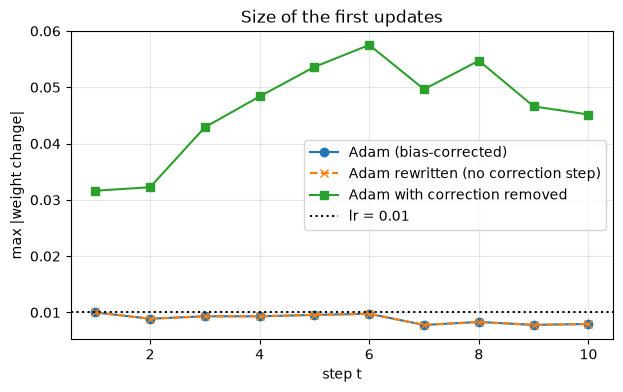

In [21]:
def first_step_sizes(optimizer, lr=0.01, n_steps=10, seed=SEED):
    """Largest weight change in each of the first optimizer steps.
    Args:
        optimizer: update function (adam, adam_no_bc, adam_raw).
        lr: learning rate.
        n_steps: number of steps to measure.
        seed: random seed (same init and minibatch order as train()).
    Returns:
        Array with max |w_t - w_{t-1}| for t = 1..n_steps.
    """
    rng = np.random.default_rng(seed)
    params = {"w": rng.normal(0, 0.01, (X.shape[1], 1)), "b": np.zeros((1, 1))}
    states = init_states(params)
    idx = rng.permutation(len(X))
    sizes = []
    for t in range(1, n_steps + 1):
        batch = idx[(t - 1) * 10: t * 10]
        w_old = params["w"].copy()
        optimizer(params, gradients(X[batch], y[batch], params["w"], params["b"]), states, t, lr=lr)
        sizes.append(np.abs(params["w"] - w_old).max())
    return np.array(sizes)

# step sizes with and without bias correction (lr = 0.01)
steps = np.arange(1, 11)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(steps, first_step_sizes(adam), "o-", label="Adam (bias-corrected)")
ax.plot(steps, first_step_sizes(adam_no_bc), "x--", label="Adam rewritten (no correction step)")
ax.plot(steps, first_step_sizes(adam_raw), "s-", label="Adam with correction removed")
ax.axhline(0.01, color="k", ls=":", label="lr = 0.01")
ax.set_xlabel("step t"); ax.set_ylabel("max |weight change|")
ax.set_title("Size of the first updates")
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "ex2_first_steps.png", dpi=150, bbox_inches="tight")
plt.show()

### Numerical verification
- **Observation:** the rewritten optimizer produces the same weights and losses as Adam, up to floating-point rounding (~$10^{-16}$).
  The rewrite is therefore exactly equivalent, not an approximation.
- **Observation:** with the correction simply removed, the first updates are about 3–5 times larger than $\eta$ (0.0316 at $t=1$, i.e. $\sqrt{1000}/10 \cdot \eta$),
  while both correct versions move each weight by about $\eta$.
- **Interpretation:** without correction, $v_1 = 0.1\,g_1$ is shrunk by a factor of 10 but $\sqrt{s_1} = \sqrt{0.001}\,|g_1|$ is shrunk by a factor of about 31.6,
  so their ratio is too large by $31.6/10 \approx 3.16$. At the start of training, when the parameters are farthest from a good solution,
  this would produce unexpectedly large steps. Bias correction, or the equivalent rewrite, keeps the step size consistent with $\eta$ from the first iteration,
  which matters for deep networks, where early instability can push the weights into poor regions.